# Binarize Mask

The following code reads a mask file (e.g., a TIFF image), converts it into a binary mask where all labeled regions are set to 1 and the background is 0, and then displays the result using Matplotlib.

Successfully created a binary mask from D:\Thesis_images\Final_dataset\all\test\B1l.tif
Original mask data type: uint32, min value: 0, max value: 61
Binary mask data type: uint8, min value: 0, max value: 1


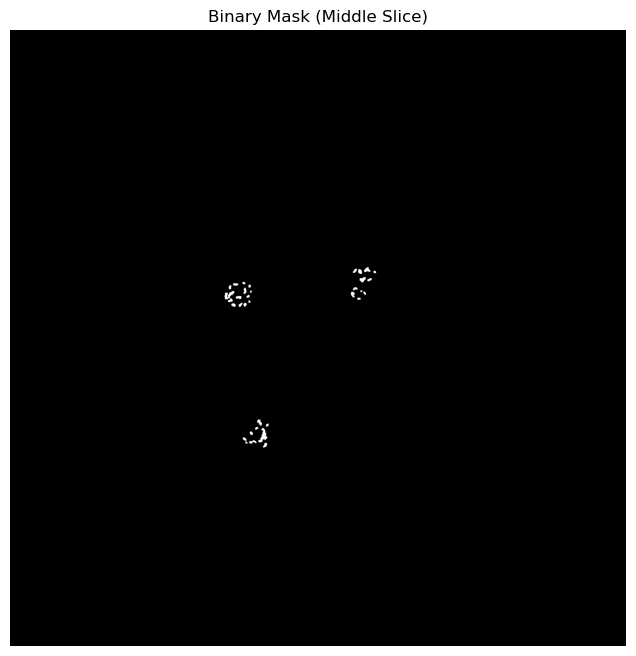

In [1]:
import tifffile
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
# Replace with the path to your mask file
INPUT_MASK_PATH = r"D:\Thesis_images\Final_dataset\all\test\B1l.tif"
# --- Binarize the Mask ---
try:
    # Read the mask file
    mask = tifffile.imread(INPUT_MASK_PATH)

    # Create a binary mask: 0 for background, 1 for any masked area
    # We create a new array of the same shape and type (or a boolean array)
    binary_mask = np.zeros_like(mask, dtype=np.uint8)
    binary_mask[mask > 0] = 1

    print(f"Successfully created a binary mask from {INPUT_MASK_PATH}")
    print(f"Original mask data type: {mask.dtype}, min value: {mask.min()}, max value: {mask.max()}")
    print(f"Binary mask data type: {binary_mask.dtype}, min value: {binary_mask.min()}, max value: {binary_mask.max()}")


    # --- Display the Output ---
    # If the mask is 3D (a stack of images), we'll display the middle slice.
    if mask.ndim == 3:
        display_slice = binary_mask[binary_mask.shape[0] // 2]
        title = f"Binary Mask (Middle Slice)"
    else:
        display_slice = binary_mask
        title = "Binary Mask"

    plt.figure(figsize=(8, 8))
    plt.imshow(display_slice, cmap='gray')
    plt.title(title)
    plt.axis('off')  # Hide axes
    plt.show()

except FileNotFoundError:
    print(f"Error: The file was not found at the specified path: {INPUT_MASK_PATH}")
except Exception as e:
    print(f"An error occurred: {e}")



# Verify Original Mask Contents

The following cell inspects the unique pixel values of the original mask file to determine if it's a binary mask, a label mask with multiple integer IDs, or something else. This helps confirm the nature of the input data.


In [2]:
print(f"slice shape: {binary_mask.shape}, unique values: {np.unique(binary_mask)}")

slice shape: (70, 1834, 1834), unique values: [0 1]



# Downscale Image

The following cell downscales the loaded 3D image to a target size of (1100, 1100) for the Y and X dimensions while keeping the Z-stack depth the same. It uses the `resize` function from `skimage.transform`. After downscaling, it prints the new shape and displays the middle slice of the resulting image.


Original shape: (70, 1834, 1834)
Downscaled shape: (70, 1100, 1100)


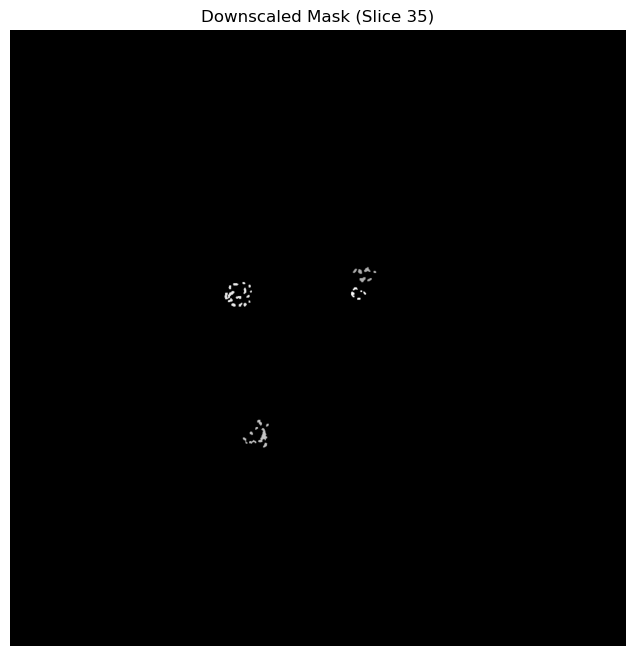

In [3]:
from skimage.transform import resize

# --- Parameters ---
# The original mask is loaded in the cell above.
# Target shape for y, x dimensions
TARGET_SHAPE = (1100, 1100)

# --- Downscale the Image ---
if 'mask' in locals() and mask.ndim == 3:
    original_shape = mask.shape
    # The new shape will be (z, new_y, new_x)
    new_shape = (original_shape[0], TARGET_SHAPE[0], TARGET_SHAPE[1])

    # Resize the 3D image
    # anti_aliasing=True is recommended for down-sampling to avoid artifacts
    downscaled_mask = resize(mask, new_shape, anti_aliasing=True, preserve_range=True)

    # The output of resize can be float, so we can cast it back if needed
    # For a mask, you might want to cast it back to an integer type.
    downscaled_mask = downscaled_mask.astype(mask.dtype)

    print(f"Original shape: {original_shape}")
    print(f"Downscaled shape: {downscaled_mask.shape}")

    # --- Display a Sample Slice ---
    middle_slice_index = downscaled_mask.shape[0] // 2
    display_slice = downscaled_mask[middle_slice_index]
    
    plt.figure(figsize=(8, 8))
    plt.imshow(display_slice, cmap='gray')
    plt.title(f"Downscaled Mask (Slice {middle_slice_index})")
    plt.axis('off')
    plt.show()
else:
    print("The 'mask' variable is not a 3D image. Please run the preceding cells to load the image first.")



# Threshold Downscaled Mask to Binary

As observed, the resizing process with anti-aliasing introduced intermediate gray values. The following cell thresholds the downscaled mask to convert it back into a clean binary mask containing only `0`s and `1`s. Any pixel value greater than 0.5 is set to `1`, and all others are set to `0`.


Final binary mask shape: (70, 1100, 1100)
Unique values in final binary mask: [0 1]


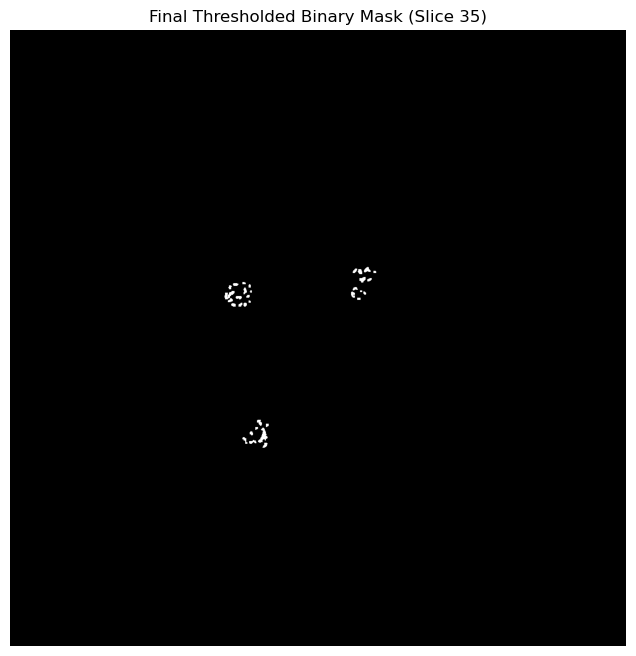

In [4]:
# --- Threshold the Downscaled Mask ---
if 'downscaled_mask' in locals():
    # Create a new binary mask by thresholding
    # Any value > 0.5 will become 1, the rest will be 0
    final_binary_mask = (downscaled_mask > 0.5).astype(np.uint8)

    print(f"Final binary mask shape: {final_binary_mask.shape}")
    print(f"Unique values in final binary mask: {np.unique(final_binary_mask)}")

    # --- Display the Final Binary Mask ---
    middle_slice_index = final_binary_mask.shape[0] // 2
    display_slice = final_binary_mask[middle_slice_index]
    
    plt.figure(figsize=(8, 8))
    plt.imshow(display_slice, cmap='gray')
    plt.title(f"Final Thresholded Binary Mask (Slice {middle_slice_index})")
    plt.axis('off')
    plt.show()
else:
    print("The 'downscaled_mask' variable is not available. Please run the preceding cells first.")



# Save the Final Mask

The following cell saves the final, downscaled, and binarized mask to a new TIFF file. The new filename is based on the original input file, with `_downsacle_imaris` appended to it.


In [5]:
import os

# --- Parameters ---
OUTPUT_DIR = r"D:\Thesis_images\Final_dataset\all\test"
SUFFIX = "_downsacle_1100_mask"

# --- Save the File ---
if 'final_binary_mask' in locals() and 'INPUT_MASK_PATH' in locals():
    # Ensure the output directory exists
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    
    # Get the base name of the input file
    base_name = os.path.basename(INPUT_MASK_PATH)
    # Get the name without the extension
    name, ext = os.path.splitext(base_name)
    
    # Construct the new filename
    new_filename = f"{name}{SUFFIX}{ext}"
    
    # Construct the full output path
    output_path = os.path.join(OUTPUT_DIR, new_filename)
    
    # Save the file
    # Using imagej=True helps maintain compatibility with ImageJ/Fiji
    tifffile.imwrite(output_path, final_binary_mask, imagej=True)
    
    print(f"File saved successfully to: {output_path}")

else:
    print("Could not save the file. Make sure 'final_binary_mask' and 'INPUT_MASK_PATH' are available from previous cells.")


File saved successfully to: D:\Thesis_images\Final_dataset\all\test\B1l_downsacle_1100_mask.tif
